# Test 03 — CIC 四点插值

彩色网格点表示四个 CIC 权重，红色圆点表示粒子位置。右图展示四个权重；权重之和应为 1。

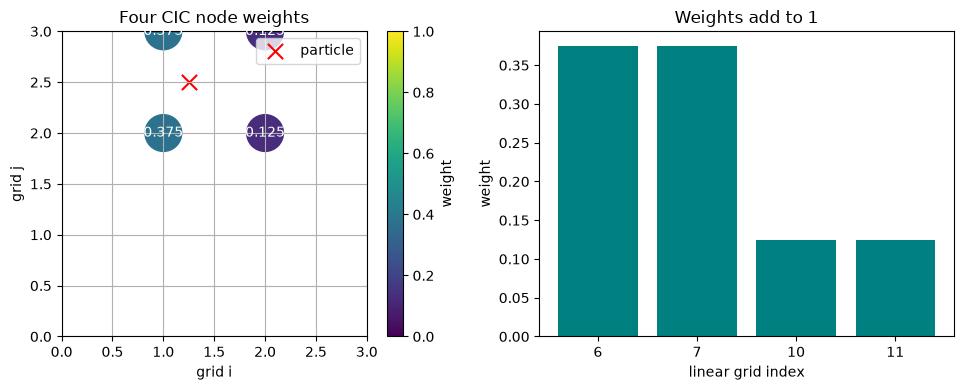

CIC weights: [0.375, 0.375, 0.125, 0.125] | interpolated: (1.25, 2.5)


In [1]:
import os, sys
from pathlib import Path
module_dir = os.environ.get('BORIS_MODULE_DIR')
if module_dir is None:
    for parent in (Path.cwd(), *Path.cwd().parents):
        for candidate in (parent / 'build', parent / 'boris_cpp' / 'build'):
            if list(candidate.glob('boris_cpp*.so')):
                module_dir = str(candidate); break
        if module_dir: break
sys.path.insert(0, module_dir or '../build')
import matplotlib.pyplot as plt
import boris_cpp as boris
%matplotlib inline

grid = boris.PeriodicGrid(boris.Vec3(0,0,0), boris.Vec3(4,4,0), (4,4,1))
point = boris.Vec3(1.25, 2.5, 99)
weights = boris.cic_weights(grid, point)
assert len(weights) == 4
assert abs(sum(w.weight for w in weights) - 1.0) < 1e-12
assert [w.cell for w in weights] == [6, 7, 10, 11]

# 构造每个节点的 (x, y, 1) 数据，插值应还原粒子所在位置。
values = [boris.Vec3(i // 4, i % 4, 1) for i in range(grid.size())]
interpolated = boris.interpolate_cic(grid, values, point)
assert abs(interpolated.x - 1.25) < 1e-12
assert abs(interpolated.y - 2.5) < 1e-12

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
xs = [w.cell // 4 for w in weights]; ys = [w.cell % 4 for w in weights]
colors = [w.weight for w in weights]
scatter = axes[0].scatter(xs, ys, c=colors, s=700, cmap='viridis', vmin=0, vmax=1)
for x, y, w in zip(xs, ys, weights): axes[0].text(x, y, f'{w.weight:.3f}', ha='center', va='center', color='white')
axes[0].scatter(point.x, point.y, marker='x', color='red', s=120, label='particle')
axes[0].set(xlabel='grid i', ylabel='grid j', title='Four CIC node weights', xlim=(0,3), ylim=(0,3), aspect='equal')
axes[0].grid(True); axes[0].legend(); fig.colorbar(scatter, ax=axes[0], label='weight')
axes[1].bar(range(4), colors, color='teal')
axes[1].set(xticks=range(4), xticklabels=[str(w.cell) for w in weights], xlabel='linear grid index', ylabel='weight', title='Weights add to 1')
plt.tight_layout(); plt.show()
print('CIC weights:', [round(w.weight, 3) for w in weights], '| interpolated:', (interpolated.x, interpolated.y))